# What Ramen does to zero-shot CLIP's confusion matrix

Compares the confusion matrix of **NoAdapt** (zero-shot CLIP, `C0`) with **Ramen** (`C1`) on the mixed stream of all five datasets, and splits the change into mechanisms instead of listing the top confused pairs (that is what the `*_confusion_probs` notebooks do).

| Section | Question |
|---|---|
| 1. Accuracy and flows | How many samples does Ramen fix, break, or move from one wrong class to another? |
| 2. Prediction marginal | Does Ramen remove *sinks* (classes predicted > 2x their true share) or create new ones? |
| 3. Bias counterfactual | How much of `C1 - C0` and of the gain is a pure class-prior shift that a per-class logit bias on NoAdapt reproduces? |
| 4. Error structure | Are the remaining errors one-way pulls to attractors or mutual confusions, and are they semantically closer to the true class? |
| 5. Per-class effects | Does Ramen level the classes up or help the already-good ones? |
| 6. Per-domain | Which domains carry each effect, and what is each domain's top error destination? |
| 7. Confusion heatmaps | `C1 - C0` itself |

All logic lives in `confusion_shift.py` (also runnable as `python confusion_shift.py analyse`). Nothing runs on the GPU: it uses the saved NoAdapt seed-0 softmax and features and Ramen's per-sample predictions for seeds 0-4. NoAdapt has no state, so its seed-0 run is realigned to every Ramen seed by (domain, sample). Tables show **mean ± std over seeds 0-4**; the detail tables and figures use seed 0.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import pandas as pd
from IPython.display import display
import confusion_shift as cs

pd.set_option('display.width', 250, 'display.max_columns', 30, 'display.max_colwidth', 40)

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Runs the analysis for every dataset (DomainNet has 596k samples and takes the longest, a few minutes for the bias fits). Each dataset also writes its CSVs to `results/confusion_shift/`.

In [2]:
res = {ds: cs.analyse_dataset(ds) for ds in cs.DATASETS}

CIFAR10C seed 0: NoAdapt 61.36 -> Ramen 72.61


CIFAR10C seed 1: NoAdapt 61.36 -> Ramen 72.68


CIFAR10C seed 2: NoAdapt 61.36 -> Ramen 72.65


CIFAR10C seed 3: NoAdapt 61.36 -> Ramen 72.53


CIFAR10C seed 4: NoAdapt 61.36 -> Ramen 72.64


...

EuroSAT seed 0: NoAdapt 48.07 -> Ramen 62.63


EuroSAT seed 1: NoAdapt 48.07 -> Ramen 62.36


EuroSAT seed 2: NoAdapt 48.07 -> Ramen 62.52


EuroSAT seed 3: NoAdapt 48.07 -> Ramen 62.68


EuroSAT seed 4: NoAdapt 48.07 -> Ramen 61.93


## 1. Accuracy and flows
`fixed` = NoAdapt wrong, Ramen right; `broken` = the reverse; `wrong_to_other_wrong` = both wrong but with different classes; `changed` = any prediction change. All are % of all samples. `ww_closer`: of the wrong-to-other-wrong samples, the % whose new wrong class is closer to the true class (prototype cosine) than the old one (50% = no direction).

In [3]:
display(cs.before_after(res, {'accuracy': 'acc'}))
cs.mean_std(res, ['fixed', 'broken', 'wrong_to_other_wrong', 'changed', 'ww_closer'])

accuracy              
                  NoAdapt         Ramen
CIFAR10C     61.36 ± 0.00  72.62 ± 0.06
CIFAR100C    37.10 ± 0.00  46.10 ± 0.04
ImageNetC5K  27.29 ± 0.00  33.03 ± 0.10
DomainNet    52.83 ± 0.00  54.55 ± 0.03
EuroSAT      48.07 ± 0.00  62.42 ± 0.30

,fixed,broken,wrong_to_other_wrong,changed,ww_closer
CIFAR10C,16.88 ± 0.04,5.61 ± 0.04,9.74 ± 0.02,32.24 ± 0.04,45.79 ± 0.15
CIFAR100C,13.55 ± 0.03,4.54 ± 0.03,29.13 ± 0.06,47.22 ± 0.06,61.44 ± 0.26
ImageNetC5K,9.57 ± 0.08,3.84 ± 0.03,39.12 ± 0.12,52.53 ± 0.16,59.69 ± 0.07
DomainNet,3.46 ± 0.03,1.73 ± 0.01,16.58 ± 0.05,21.77 ± 0.06,41.78 ± 0.27
EuroSAT,18.27 ± 0.34,3.91 ± 0.06,10.74 ± 0.13,32.92 ± 0.33,56.06 ± 1.02


## 2. Prediction marginal: sinks and starved classes
Per class, `ratio = predicted share / true share`.
- `tv_to_true`: total-variation distance between the predicted and the true class distribution (% of samples that would have to change class to match). `tv_to_true_dom` uses each domain's own label distribution, averaged over domains.
- `sink_pred_share`: % of all predictions that go to sink classes (ratio > 2).
- `starved_classes`: % of classes predicted less than half as often as they occur.
- `eff_pred_classes`: effective number of predicted classes (exp of the entropy) as % of the true effective number; below 100 = predictions concentrated on fewer classes.

In [4]:
cs.before_after(res, {'TV to true (%)': 'tv_to_true', 'TV per domain (%)': 'tv_to_true_dom',
                      'sink share (%)': 'sink_pred_share', 'starved classes (%)': 'starved_classes',
                      'eff. predicted classes (%)': 'eff_pred_classes'})

TV to true (%)               TV per domain (%)               sink share (%)               starved classes (%)               eff. predicted classes (%)              
                   NoAdapt         Ramen           NoAdapt         Ramen        NoAdapt         Ramen             NoAdapt         Ramen                    NoAdapt         Ramen
CIFAR10C       9.87 ± 0.00   5.42 ± 0.06      16.53 ± 0.00   9.62 ± 0.06    0.00 ± 0.00   0.00 ± 0.00         0.00 ± 0.00   0.00 ± 0.00               95.60 ± 0.00  98.88 ± 0.02
CIFAR100C     26.44 ± 0.00  17.07 ± 0.10      33.51 ± 0.00  23.93 ± 0.05   27.03 ± 0.00   2.93 ± 1.11        23.00 ± 0.00  12.20 ± 0.45               80.25 ± 0.00  91.49 ± 0.09
ImageNetC5K   31.89 ± 0.00  25.34 ± 0.10      44.11 ± 0.00  34.91 ± 0.13   30.46 ± 0.00  21.33 ± 0.45        26.68 ± 0.00  19.10 ± 0.43               70.29 ± 0.00  91.94 ± 0.09
DomainNet     20.58 ± 0.00  17.96 ± 0.07      25.15 ± 0.00  23.06 ± 0.06   16.21 ± 0.00  13.56 ± 0.26         8.12 ± 0.00   6.96 ± 0.00               74.02 ± 0.00  87.71 ± 0.12
EuroSAT       29.77 ± 0.00  25.08 ± 0.41      29.77 ± 0.00  25.08 ± 0.41   26.41 ± 0.00  21.28 ± 0.27        30.00 ± 0.00  20.00 ± 0.00               76.71 ± 0.00  80.11 ± 0.43

Each dot is one class: x = NoAdapt's `log2(ratio)`, y = Ramen's. Dots below the diagonal are predicted less after Ramen. The shaded bands mark sinks (ratio > 2); the floor at -6 means a class that is (almost) never predicted. Labels mark the 4 classes whose ratio changed most.

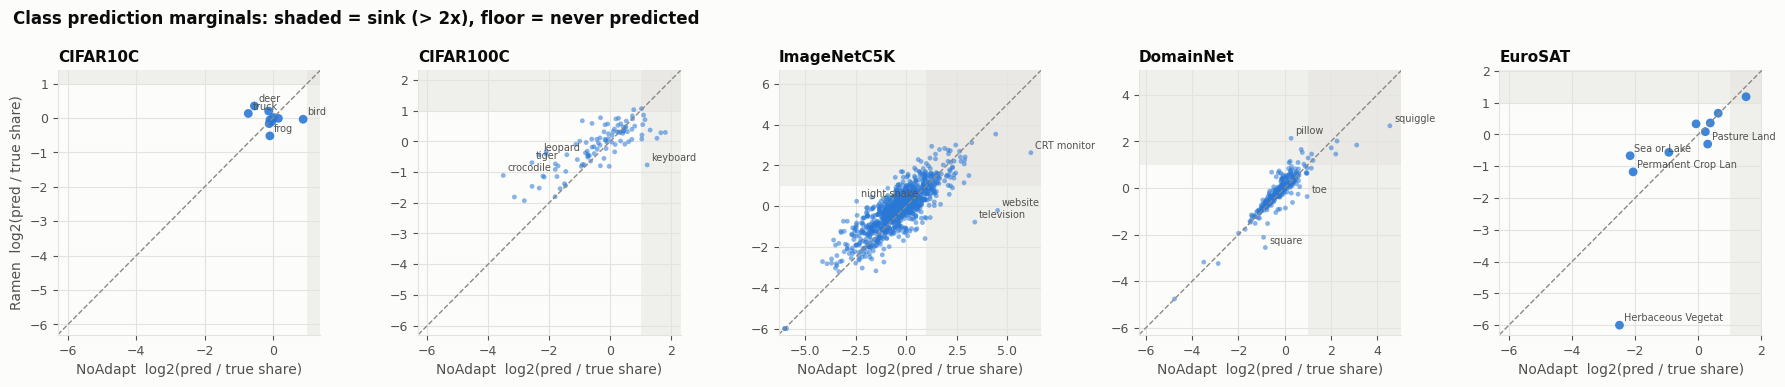

In [5]:
cs.plot_marginals(res);

Do the fixes come out of the sinks? `noadapt_err_in_sinks` = % of NoAdapt's errors that land in a NoAdapt sink. `fixed_from_sinks` = % of Ramen's fixed samples whose NoAdapt prediction was a sink. If Ramen fixed errors regardless of where they went, the two would be equal. `broken_into_new_sinks` = % of Ramen's new errors that land in classes only Ramen turns into sinks.

The `_dom` columns define sinks within each domain (a class predicted > 2x its share *in that corruption/domain*). The attractors are mostly domain-specific: CIFAR-10-C has no global sink, yet `bird` takes 41% of the predictions under gaussian noise.

In [6]:
cs.mean_std(res, ['noadapt_err_in_sinks', 'fixed_from_sinks', 'broken_into_new_sinks',
                  'noadapt_err_in_sinks_dom', 'fixed_from_sinks_dom', 'broken_into_new_sinks_dom'])

,noadapt_err_in_sinks,fixed_from_sinks,broken_into_new_sinks,noadapt_err_in_sinks_dom,fixed_from_sinks_dom,broken_into_new_sinks_dom
CIFAR10C,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,20.13 ± 0.00,20.88 ± 0.04,0.00 ± 0.00
CIFAR100C,33.91 ± 0.00,33.37 ± 0.12,0.95 ± 1.30,45.09 ± 0.00,42.88 ± 0.16,10.28 ± 0.35
ImageNetC5K,37.88 ± 0.00,34.71 ± 0.17,10.91 ± 0.57,54.62 ± 0.00,52.44 ± 0.15,17.82 ± 0.31
DomainNet,31.14 ± 0.00,32.02 ± 0.24,7.49 ± 0.43,47.55 ± 0.00,46.87 ± 0.13,11.87 ± 0.39
EuroSAT,38.11 ± 0.00,45.83 ± 0.28,0.00 ± 0.00,38.11 ± 0.00,45.83 ± 0.28,0.00 ± 0.00


Sinks shrink a lot, but the fixes do not come out of them preferentially (`fixed_from_sinks_dom` ≈ `noadapt_err_in_sinks_dom`). So where do the sink errors go? For seed 0, NoAdapt's errors split by whether they sit in a domain sink, and what Ramen does with them (% of that group).

In [7]:
cs.sink_error_fate(res)

% of errors  fixed  moved to other wrong  unchanged
dataset     NoAdapt error                                                        
CIFAR10C    in a domain sink         20.1   45.6                  38.2       16.3
            elsewhere                79.9   43.3                  21.9       34.8
CIFAR100C   in a domain sink         45.1   20.5                  54.7       24.9
            elsewhere                54.9   22.4                  39.6       38.1
ImageNetC5K in a domain sink         54.6   12.7                  61.6       25.6
            elsewhere                45.4   13.8                  44.3       41.9
DomainNet   in a domain sink         47.5    7.1                  48.8       44.1
            elsewhere                52.5    7.4                  23.0       69.7
EuroSAT     in a domain sink         38.1   43.4                  13.9       42.8
            elsewhere                61.9   31.0                  24.6       44.4

Top sinks before and after (seed 0), plus the classes Ramen starves most, ranked by **excess** = predicted count - true count (the absolute number of predictions a class absorbs; the ratio alone is noisy for ImageNetC5K classes with only 15 samples). `ratio_*` = predicted / true share.

In [8]:
cols = ['class', 'true_n', 'excess_noadapt', 'excess_ramen', 'ratio_noadapt', 'ratio_ramen', 'acc_noadapt', 'acc_ramen']
for ds, r in res.items():
    sk = r['sinks'][r['sinks'].true_n > 0][cols]
    print(f'==== {ds}')
    display(pd.concat({'top NoAdapt sinks': sk.sort_values('excess_noadapt', ascending=False).head(6).reset_index(drop=True),
                       'top Ramen sinks': sk.sort_values('excess_ramen', ascending=False).head(6).reset_index(drop=True),
                       'most starved by Ramen': sk.sort_values('excess_ramen').head(6).reset_index(drop=True)},
                      axis=1).round(2))

==== CIFAR10C


top NoAdapt sinks                                                                                    top Ramen sinks                                                                                    most starved by Ramen                        \
              class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen           class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen                 class true_n excess_noadapt   
0              bird  15000          12786         -339          1.85        0.98       69.87     64.47            deer  15000          -4673         4154          0.69        1.28       46.64     75.93                  frog  15000           -854   
1               dog  15000           1806          -75          1.12        1.00       58.05     66.81           horse  15000          -1207         2280          0.92        1.15       71.16     83.52              airplane  15000          -1043   
2        automobile  15000            207          187          1.01        1.01       73.41     81.01           truck  15000          -5880         1470          0.61        1.10       51.93     84.88                   cat  15000           -305   
3               cat  15000           -305        -1047          0.98        0.93       52.27     60.21      automobile  15000            207          187          1.01        1.01       73.41     81.01                  ship  15000           -837   
4              ship  15000           -837         -528          0.94        0.96       68.77     80.79             dog  15000           1806          -75          1.12        1.00       58.05     66.81                  bird  15000          12786   
5              frog  15000           -854        -4519          0.94        0.70       55.29     54.07            bird  15000          12786         -339          1.85        0.98       69.87     64.47                   dog  15000           1806   

                                                                
  excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen  
0        -4519          0.94        0.70       55.29     54.07  
1        -1583          0.93        0.89       66.17     74.41  
2        -1047          0.98        0.93       52.27     60.21  
3         -528          0.94        0.96       68.77     80.79  
4         -339          1.85        0.98       69.87     64.47  
5          -75          1.12        1.00       58.05     66.81

==== CIFAR100C


top NoAdapt sinks                                                                                    top Ramen sinks                                                                                    most starved by Ramen                        \
              class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen           class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen                 class true_n excess_noadapt   
0              worm   1500           3778          337          3.52        1.22       68.00     56.67             fox   1500           1563         1643          2.04        2.10       56.47     65.27                   ray   1500          -1287   
1             mouse   1500           3263          322          3.18        1.21       14.73     15.80        oak_tree   1500           1069         1568          1.71        2.05       52.07     58.80               lobster   1500          -1330   
2              girl   1500           2856          110          2.90        1.07       53.33     50.27         hamster   1500           1714         1215          2.14        1.81       50.93     62.27                 table   1500          -1071   
3       willow_tree   1500           2230          438          2.49        1.29       44.87     37.47        mountain   1500            992         1174          1.66        1.78       67.20     75.60              wardrobe   1500          -1019   
4          keyboard   1500           1988         -619          2.33        0.59       62.13     41.67         tractor   1500           -294         1057          0.80        1.70       44.00     68.87                   bed   1500          -1201   
5         pine_tree   1500           1819          948          2.21        1.63       43.87     50.60          possum   1500            318         1030          1.21        1.69       29.07     43.00           caterpillar   1500          -1246   

                                                                
  excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen  
0        -1107          0.14        0.26        2.80      9.27  
1        -1073          0.11        0.28        4.47     12.00  
2        -1070          0.29        0.29       17.00     21.67  
3         -984          0.32        0.34       22.60     28.33  
4         -978          0.20        0.35       12.60     22.93  
5         -957          0.17        0.36       10.20     23.60

==== ImageNetC5K


top NoAdapt sinks                                                                                    top Ramen sinks                                                                                    most starved by Ramen                        \
              class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen           class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen                 class true_n excess_noadapt   
0       CRT monitor     45           3178          232         71.62        6.16       46.67     35.56   window screen     45            921          477         21.47       11.60       57.78     73.33              envelope    180           -128   
1           website     60           1314           -8         22.90        0.87       51.67     38.33     CRT monitor     45           3178          232         71.62        6.16       46.67     35.56         assault rifle    150           -120   
2        television    120           1139          -50         10.49        0.58       15.83     15.00     rain barrel     75             86          220          2.15        3.93       28.00     60.00            promontory    120           -118   
3     window screen     45            921          477         21.47       11.60       57.78     73.33       rock crab     90            -10          200          0.89        3.22       12.22     21.11           mixing bowl    165           -131   
4     velvet fabric     60            455          110          8.58        2.83        3.33      5.00    Brittany dog    105            372          175          4.54        2.67       15.24     13.33                cradle    120           -108   
5     jigsaw puzzle     60            376           73          7.27        2.22       41.67     46.67    mosquito net     45             23          175          1.51        4.89        2.22      8.89                diaper    165            -88   

                                                                
  excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen  
0         -138          0.29        0.23       12.78     12.22  
1         -122          0.20        0.19       15.33     13.33  
2         -120          0.02        0.00        0.00      0.00  
3         -117          0.21        0.29        6.67      9.09  
4         -107          0.10        0.11        0.83      0.00  
5         -106          0.47        0.36       16.36     16.97

==== DomainNet


top NoAdapt sinks                                                                                    top Ramen sinks                                                                                    most starved by Ramen                        \
              class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen           class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen                 class true_n excess_noadapt   
0          squiggle   1950          43621        10429         23.37        6.35       48.10     35.13        squiggle   1950          43621        10429         23.37        6.35       48.10     35.13                   cup   2064          -1783   
1          envelope   1846          14123         4759          8.65        3.58       74.86     70.53          pillow   1736            365         5869          1.21        4.38       54.90     64.57                square   1843           -813   
2              pear   1758           6663         5329          4.79        4.03       73.89     72.47            pear   1758           6663         5329          4.79        4.03       73.89     72.47                  nail   2332          -1284   
3       smiley_face   1403           5077         2441          4.62        2.74       65.50     65.72          teapot   2280           1453         4885          1.64        3.14       77.63     83.29           streetlight   2207          -1379   
4         boomerang   1426           4322         3272          4.03        3.29       44.60     41.73        envelope   1846          14123         4759          8.65        3.58       74.86     70.53                marker   1280          -1233   
5          triangle   2024           2464         1618          2.22        1.80       67.79     68.08          helmet   1785           1237         3343          1.69        2.87       64.20     71.43             golf_club   2773          -1196   

                                                                
  excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen  
0        -1846          0.14        0.11        7.36      5.23  
1        -1530          0.56        0.17        6.46      5.75  
2        -1374          0.45        0.41       38.68     36.71  
3        -1266          0.38        0.43       33.35     36.97  
4        -1233          0.04        0.04        1.09      1.02  
5        -1204          0.57        0.57       50.85     50.56

==== EuroSAT


top NoAdapt sinks                                                                                           top Ramen sinks                                                                                          most starved by Ramen  \
                   class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen                  class true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen                       class   
0        Highway or Road   2500           4630         3173          2.85        2.27       71.44     91.92        Highway or Road   2500           4630         3173          2.85        2.27       71.44     91.92  Herbaceous Vegetation Land   
1       Annual Crop Land   3000           1640         1754          1.55        1.58       67.80     91.20       Annual Crop Land   3000           1640         1754          1.55        1.58       67.80     91.20         Permanent Crop Land   
2  Residential Buildings   3000            897          845          1.30        1.28       95.73     99.33  Residential Buildings   3000            897          845          1.30        1.28       95.73     99.33                 Sea or Lake   
3           Pasture Land   2000            455         -383          1.23        0.81       53.60     46.45                 Forest   3000           -146          767          0.95        1.26       34.97     72.30                       River   
4   Industrial Buildings   2500            416          148          1.17        1.06       81.52     88.68   Industrial Buildings   2500            416          148          1.17        1.06       81.52     88.68                Pasture Land   
5                 Forest   3000           -146          767          0.95        1.26       34.97     72.30           Pasture Land   2000            455         -383          1.23        0.81       53.60     46.45        Industrial Buildings   

                                                                                      
  true_n excess_noadapt excess_ramen ratio_noadapt ratio_ramen acc_noadapt acc_ramen  
0   3000          -2469        -2979          0.18        0.01        6.67      0.30  
1   2500          -1903        -1397          0.24        0.44       14.36     19.80  
2   3000          -2329        -1118          0.22        0.63       13.10     54.40  
3   2500          -1191         -810          0.52        0.68       47.00     57.80  
4   2000            455         -383          1.23        0.81       53.60     46.45  
5   2500            416          148          1.17        1.06       81.52     88.68

## 3. Bias counterfactual: is Ramen a class-prior shift?
NoAdapt's log-probabilities plus a per-class bias `b`, fitted so the argmax predictions have a given class count:
- **Ramen marginal (global)**: `b` matches Ramen's predicted class counts over the whole stream (K parameters).
- **Ramen marginal (per domain)**: a separate `b` per domain matched to Ramen's per-domain counts (K x domains parameters, so it can fit more; on ImageNet-C that is 15 x 1000 parameters for 5 samples per class per domain, which flatters it).
- **true marginal (per domain, oracle)**: `b` matches the true labels' counts per domain: the ceiling of any per-domain prior correction.

`dC_explained` = `1 - |C1 - Cb| / |C1 - C0|` (L1 over the count matrix): the share of Ramen's confusion change that the bias reproduces. `ramen_changes_reproduced` = of the samples whose prediction Ramen changed, the % the bias changes to the same class. `fit_mismatch_tv` = how close the fitted counts got to the target (%).

In [9]:
cf = pd.concat([r['cf'] for r in res.values()])
cf_cols = ['gain', 'acc', 'agree_with_ramen', 'dC_explained', 'ramen_changes_reproduced', 'fit_mismatch_tv']
cf.groupby(['dataset', 'variant'], sort=False)[cf_cols].mean().round(2)

gain    acc  agree_with_ramen  dC_explained  ramen_changes_reproduced  fit_mismatch_tv
dataset     variant                                                                                                                          
CIFAR10C    bias: Ramen marginal (global)              0.82  62.17             70.66         42.42                     23.92             0.09
            bias: Ramen marginal (per domain)          2.25  63.61             73.37         50.33                     31.78             0.10
            bias: true marginal (per domain, oracle)   3.65  65.01             71.55         43.93                     26.13             0.09
            Ramen                                     11.27  72.62            100.00        100.00                    100.00              NaN
CIFAR100C   bias: Ramen marginal (global)              0.59  37.69             54.62         34.13                     12.77             0.12
            bias: Ramen marginal (per domain)          1.48  38.57             56.89         40.33                     19.17             0.20
            bias: true marginal (per domain, oracle)   3.70  40.80             49.99          1.66                     15.94             0.20
            Ramen                                      9.00  46.10            100.00        100.00                    100.00              NaN
ImageNetC5K bias: Ramen marginal (global)              0.19  27.48             49.62         11.71                     13.64             0.16
            bias: Ramen marginal (per domain)          1.32  28.61             54.78         19.08                     23.76             1.29
            bias: true marginal (per domain, oracle)   4.82  32.11             40.66        -12.42                     15.21             4.49
            Ramen                                      5.74  33.03            100.00        100.00                    100.00              NaN
DomainNet   bias: Ramen marginal (global)              0.57  53.39             81.16         39.69                     31.64             0.06
            bias: Ramen marginal (per domain)          1.12  53.95             83.00         49.76                     35.09             0.13
            bias: true marginal (per domain, oracle)   3.84  56.67             66.05        -62.97                     19.94             0.22
            Ramen                                      1.73  54.55            100.00        100.00                    100.00              NaN
EuroSAT     bias: Ramen marginal (global)              3.83  51.90             70.17         17.88                     19.18             0.25
            bias: Ramen marginal (per domain)          3.83  51.90             70.17         17.88                     19.18             0.25
            bias: true marginal (per domain, oracle)  10.44  58.51             59.46        -42.77                     25.91             0.23
            Ramen                                     14.36  62.42            100.00        100.00                    100.00              NaN

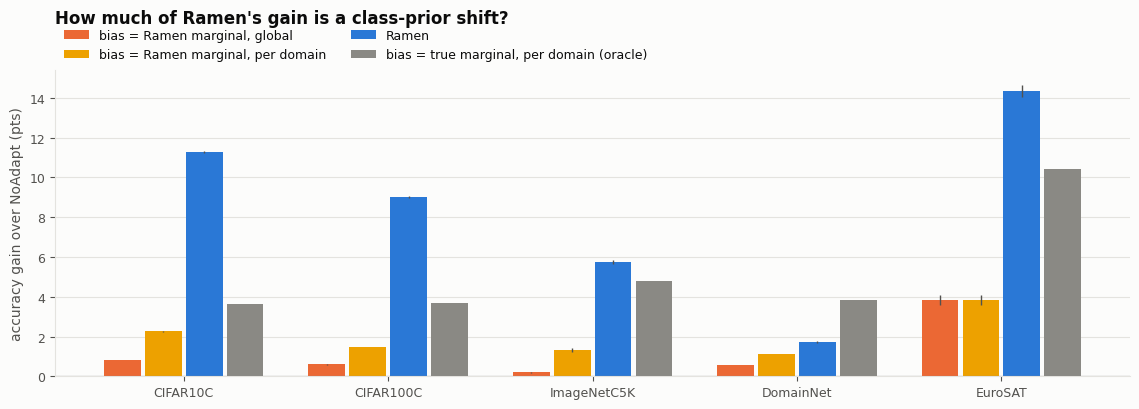

In [10]:
cs.plot_counterfactual(res);

## 4. Error structure
- `asymmetry`: `sum|C_ij - C_ji| / sum(C_ij + C_ji)` over class pairs. 100 = every confusion is one-way (A is called B, B is never called A: an attractor pulling), 0 = perfectly mutual (two classes that look alike).
- `eff_error_dest`: effective number of classes the errors land in, as % of all classes. Low = errors pile onto a few destinations.
- `top5_dest_share`: % of errors that land in the 5 most common error classes.
- `err_rank`: mean neighbour rank of the predicted class among the true class's classes, ordered by prototype cosine (class-mean NoAdapt image feature). 0 = the nearest class, 0.5 = chance, 1 = the farthest.
- `err_nn1`: % of errors that go to the true class's single nearest class.
- `err_same_group`: % of errors within the same superclass (CIFAR-100 superclasses; CIFAR-10 vehicle/animal; EuroSAT vegetation/built/water).

In [11]:
metrics = {'asymmetry': 'asymmetry', 'eff. error dest. (%)': 'eff_error_dest', 'top-5 dest. share (%)': 'top5_dest_share',
           'error rank (0=nearest)': 'err_rank', 'into nearest class (%)': 'err_nn1'}
display(cs.before_after(res, metrics))
cs.before_after({ds: r for ds, r in res.items() if r['run'].group is not None}, {'same superclass (%)': 'err_same_group'})

asymmetry               eff. error dest. (%)               top-5 dest. share (%)               error rank (0=nearest)              into nearest class (%)              
                  NoAdapt         Ramen              NoAdapt         Ramen               NoAdapt         Ramen                NoAdapt        Ramen                NoAdapt         Ramen
CIFAR10C     44.77 ± 0.00  34.84 ± 0.12         80.31 ± 0.00  92.45 ± 0.17          72.99 ± 0.00  66.79 ± 0.23            0.24 ± 0.00  0.26 ± 0.00           31.80 ± 0.00  33.88 ± 0.12
CIFAR100C    66.91 ± 0.00  57.57 ± 0.20         68.65 ± 0.00  82.51 ± 0.17          19.16 ± 0.00  12.34 ± 0.06            0.28 ± 0.00  0.22 ± 0.00           10.49 ± 0.00  12.74 ± 0.06
ImageNetC5K  88.17 ± 0.00  86.80 ± 0.11         52.40 ± 0.00  76.31 ± 0.13          13.27 ± 0.00   3.06 ± 0.05            0.20 ± 0.00  0.16 ± 0.00            6.19 ± 0.00   7.64 ± 0.05
DomainNet    76.14 ± 0.00  72.02 ± 0.11         40.51 ± 0.00  64.75 ± 0.26          27.39 ± 0.00  12.70 ± 0.08            0.20 ± 0.00  0.23 ± 0.00            8.58 ± 0.00   8.76 ± 0.01
EuroSAT      85.57 ± 0.00  93.72 ± 0.12         61.55 ± 0.00  63.95 ± 0.67          86.74 ± 0.00  85.31 ± 0.46            0.43 ± 0.00  0.36 ± 0.00           12.27 ± 0.00  16.54 ± 0.57

same superclass (%)              
                      NoAdapt         Ramen
CIFAR10C         77.64 ± 0.00  82.78 ± 0.08
CIFAR100C        24.59 ± 0.00  29.01 ± 0.09
EuroSAT          42.14 ± 0.00  50.85 ± 0.38

Cumulative distribution of the neighbour rank of the predicted class over all errors. A curve above the chance diagonal means errors go to similar-looking classes; a curve that moves up after Ramen means its remaining errors are more "reasonable".

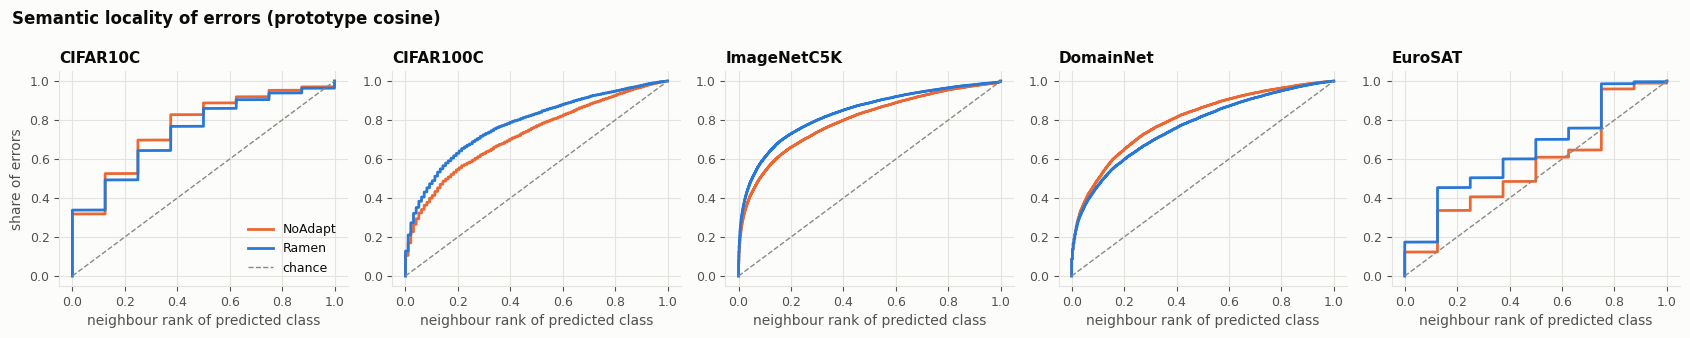

In [12]:
cs.plot_locality(res);

## 5. Per-class effects
- `class_acc_std`: spread of the per-class accuracies.
- `worst_decile`: mean accuracy of NoAdapt's worst 10% of classes, before (0) and after (1) Ramen.
- `classes_up` / `classes_down`: % of classes whose accuracy rises / falls.
- `rho_acc0_gain`: Spearman correlation between a class's NoAdapt accuracy and its gain. Negative = levelling (weak classes gain most), positive = rich get richer.

In [13]:
display(cs.before_after(res, {'class acc. std': 'class_acc_std', 'worst decile acc.': 'worst_decile'}))
cs.mean_std(res, ['classes_up', 'classes_down', 'rho_acc0_gain'])

class acc. std               worst decile acc.              
                   NoAdapt         Ramen           NoAdapt         Ramen
CIFAR10C       9.10 ± 0.00  10.05 ± 0.06      46.64 ± 0.00  76.20 ± 0.25
CIFAR100C     18.48 ± 0.00  17.11 ± 0.05       8.05 ± 0.00  18.94 ± 0.14
ImageNetC5K   19.53 ± 0.00  21.30 ± 0.05       1.98 ± 0.00   5.53 ± 0.24
DomainNet     15.44 ± 0.00  16.33 ± 0.02      19.60 ± 0.00  19.42 ± 0.05
EuroSAT       29.33 ± 0.00  31.45 ± 0.15       6.67 ± 0.00   0.32 ± 0.04

,classes_up,classes_down,rho_acc0_gain
CIFAR10C,80.00 ± 0.00,20.00 ± 0.00,-0.42 ± 0.00
CIFAR100C,88.40 ± 0.55,11.60 ± 0.55,-0.38 ± 0.01
ImageNetC5K,75.89 ± 0.56,15.73 ± 0.55,0.11 ± 0.01
DomainNet,78.32 ± 0.83,20.93 ± 0.83,0.21 ± 0.01
EuroSAT,80.00 ± 0.00,20.00 ± 0.00,-0.07 ± 0.06


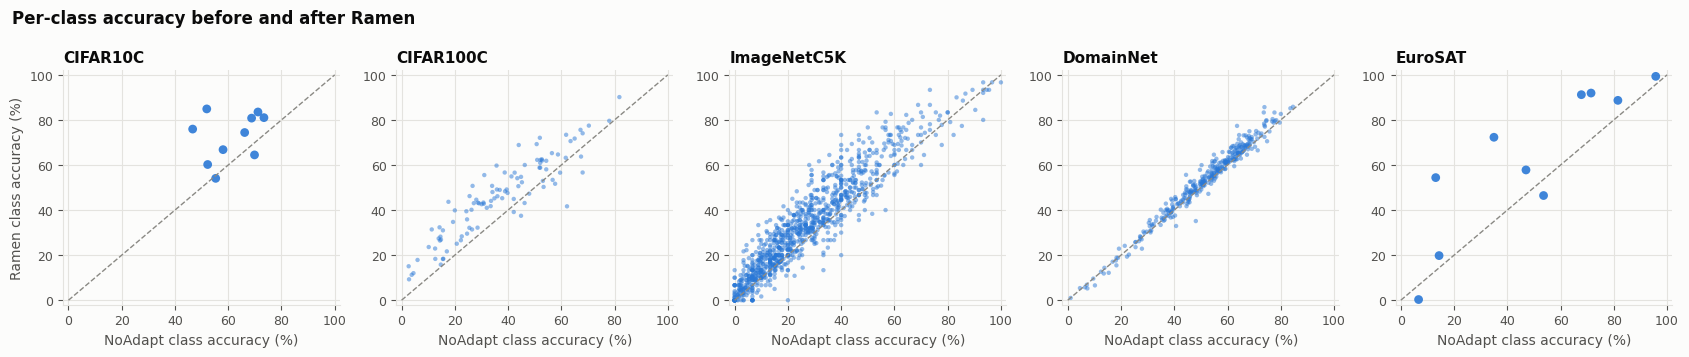

In [14]:
cs.plot_class_acc(res);

## 6. Per domain (seed 0)
Suffix 0 = NoAdapt, 1 = Ramen. `tv`, `sink_share` as in section 2 but against the domain's own label distribution; `asym` and `err_rank` as in section 4; `top_dest` = the single most common error destination in that domain and `top_dest_share` = the % of the domain's errors that go there.

In [15]:
for ds, r in res.items():
    if len(r['doms']) > 1:
        print(f'==== {ds}')
        display(r['doms'].set_index('domain').round(2))

==== CIFAR10C


,acc0,tv0,sink_share0,asym0,err_rank0,top_dest0,top_dest_share0,acc1,tv1,sink_share1,asym1,err_rank1,top_dest1,top_dest_share1
domain,,,,,,,,,,,,,,
gaussian_noise,38.66,35.00,41.02,82.26,0.24,bird,53.52,60.84,11.96,0.0,48.11,0.31,deer,18.54
shot_noise,42.59,34.09,33.75,79.79,0.25,bird,45.64,63.14,11.48,0.0,50.19,0.31,deer,18.48
impulse_noise,42.75,29.36,30.84,72.96,0.23,bird,41.41,56.27,19.47,0.0,57.28,0.31,horse,18.91
defocus_blur,72.61,9.41,0.00,51.00,0.22,dog,23.33,77.12,8.14,0.0,58.22,0.24,deer,25.74
glass_blur,43.91,25.11,27.49,61.38,0.29,bird,39.38,64.01,7.83,0.0,36.59,0.29,dog,17.09
motion_blur,66.68,16.03,0.00,62.06,0.19,bird,33.01,77.55,8.54,0.0,52.07,0.22,bird,29.80
zoom_blur,71.69,11.77,0.00,55.78,0.19,bird,28.05,79.27,8.46,0.0,60.73,0.21,deer,29.72
snow,73.78,7.77,0.00,41.42,0.22,cat,23.00,80.65,7.39,0.0,58.97,0.22,deer,27.03
frost,75.69,6.75,0.00,37.15,0.19,bird,25.83,80.16,7.98,0.0,58.77,0.21,deer,35.43


==== CIFAR100C


,acc0,tv0,sink_share0,asym0,err_rank0,top_dest0,top_dest_share0,acc1,tv1,sink_share1,asym1,err_rank1,top_dest1,top_dest_share1
domain,,,,,,,,,,,,,,
gaussian_noise,22.83,46.39,54.95,88.05,0.31,mouse,16.21,30.37,37.30,40.55,82.36,0.26,lawn_mower,6.13
shot_noise,24.42,44.06,50.67,87.46,0.29,mouse,18.18,31.98,34.44,39.00,80.21,0.24,mouse,6.87
impulse_noise,29.58,44.07,52.98,89.41,0.24,mouse,21.60,42.94,28.11,28.14,79.32,0.22,mouse,7.80
defocus_blur,43.56,27.29,22.40,78.53,0.25,fox,6.89,52.60,19.21,5.33,72.87,0.20,fox,4.73
glass_blur,20.16,52.14,64.09,89.68,0.37,pine_tree,14.59,28.95,36.51,39.58,81.39,0.29,crab,6.04
motion_blur,43.60,26.54,21.45,76.42,0.24,worm,5.59,52.38,17.74,5.49,70.22,0.20,beaver,5.61
zoom_blur,48.64,24.51,16.96,77.80,0.23,fox,8.18,55.74,18.46,9.38,75.01,0.20,fox,5.24
snow,48.91,22.08,15.19,75.34,0.22,willow_tree,6.26,55.30,16.46,4.78,71.77,0.18,willow_tree,4.34
frost,50.48,20.94,11.86,74.96,0.20,flatfish,7.67,54.40,18.72,13.30,74.43,0.16,flatfish,7.15


==== ImageNetC5K


,acc0,tv0,sink_share0,asym0,err_rank0,top_dest0,top_dest_share0,acc1,tv1,sink_share1,asym1,err_rank1,top_dest1,top_dest_share1
domain,,,,,,,,,,,,,,
gaussian_noise,15.00,58.56,60.60,98.64,0.27,CRT monitor,27.72,22.24,41.16,40.90,97.94,0.20,window screen,1.62
shot_noise,16.88,54.92,56.50,98.60,0.25,CRT monitor,22.35,23.18,40.18,41.10,97.55,0.19,rock crab,1.77
impulse_noise,15.36,59.76,62.40,98.39,0.24,CRT monitor,14.46,23.64,38.28,38.58,97.12,0.19,window screen,2.49
defocus_blur,25.68,37.70,36.42,96.88,0.18,lens cap,1.35,28.52,33.02,29.82,95.36,0.16,Brittany dog,0.87
glass_blur,16.90,52.00,55.98,97.83,0.23,feather boa,3.42,24.20,40.60,41.42,96.78,0.19,feather boa,1.79
motion_blur,26.82,39.74,42.08,96.39,0.20,CRT monitor,1.89,32.88,31.40,29.74,94.87,0.15,three-toed sloth,0.72
zoom_blur,24.58,45.22,47.32,96.55,0.20,Siamese cat,1.78,29.76,36.66,35.00,95.50,0.16,porcupine,1.68
snow,34.00,38.60,37.30,95.70,0.15,umbrella,10.73,37.40,34.44,32.42,95.72,0.14,rain barrel,3.23
frost,33.02,39.12,37.50,96.24,0.16,window screen,15.20,34.98,37.60,35.82,96.19,0.16,window screen,5.26


==== DomainNet


,acc0,tv0,sink_share0,asym0,err_rank0,top_dest0,top_dest_share0,acc1,tv1,sink_share1,asym1,err_rank1,top_dest1,top_dest_share1
domain,,,,,,,,,,,,,,
clipart,68.25,14.51,6.50,83.42,0.19,smiley_face,3.85,69.33,13.84,5.13,82.79,0.19,zigzag,2.89
infograph,43.90,31.76,33.13,85.08,0.28,spreadsheet,9.03,44.98,29.95,30.33,84.05,0.28,spreadsheet,6.86
painting,64.58,16.54,13.45,82.70,0.23,paintbrush,3.91,65.70,15.87,11.02,82.19,0.24,paintbrush,2.54
quickdraw,13.33,62.02,61.95,95.88,0.19,squiggle,29.05,17.54,53.97,62.72,91.79,0.25,squiggle,7.77
real,82.12,7.62,0.62,75.20,0.14,peas,1.78,82.27,7.50,0.31,75.85,0.15,peas,1.80
sketch,60.05,18.42,11.90,81.58,0.21,squiggle,2.42,60.96,17.62,9.53,81.21,0.22,mermaid,1.59


## 7. Confusion heatmaps
Row-normalised (% of the true class). For CIFAR-10-C and EuroSAT: NoAdapt, Ramen and the difference. For the larger label spaces only the difference, restricted to the 24 classes with the largest off-diagonal change. Blue = Ramen predicts that cell more often, red = less often; on the diagonal blue is a gain.

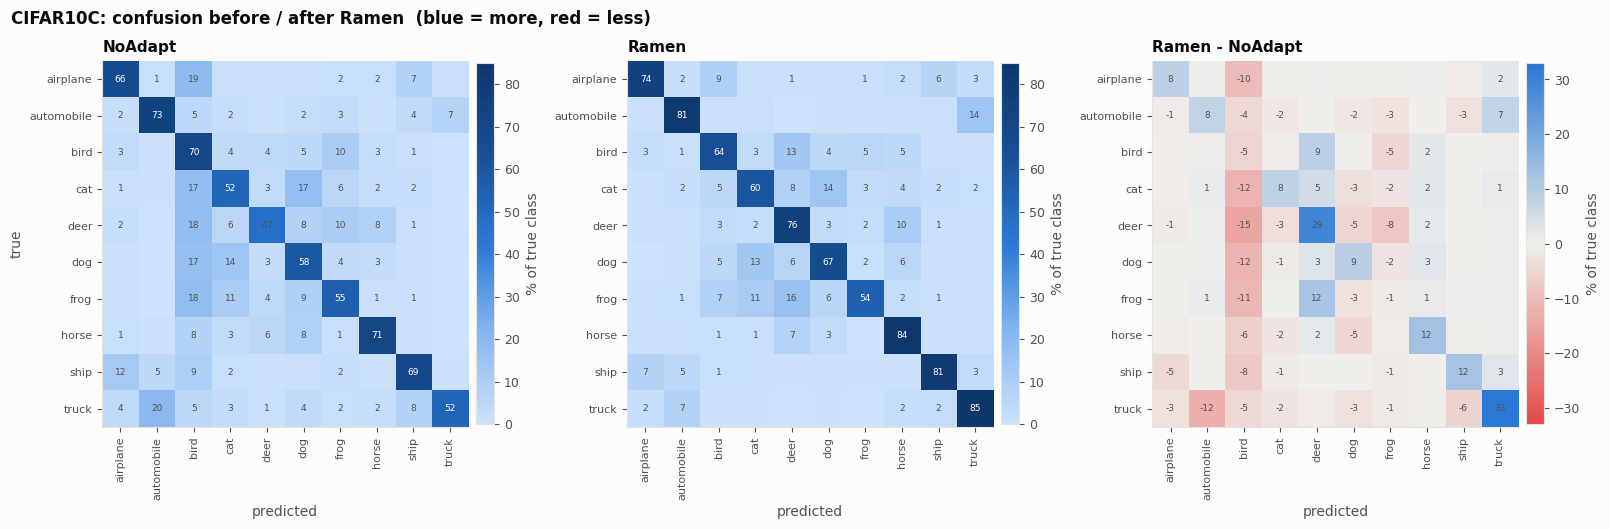

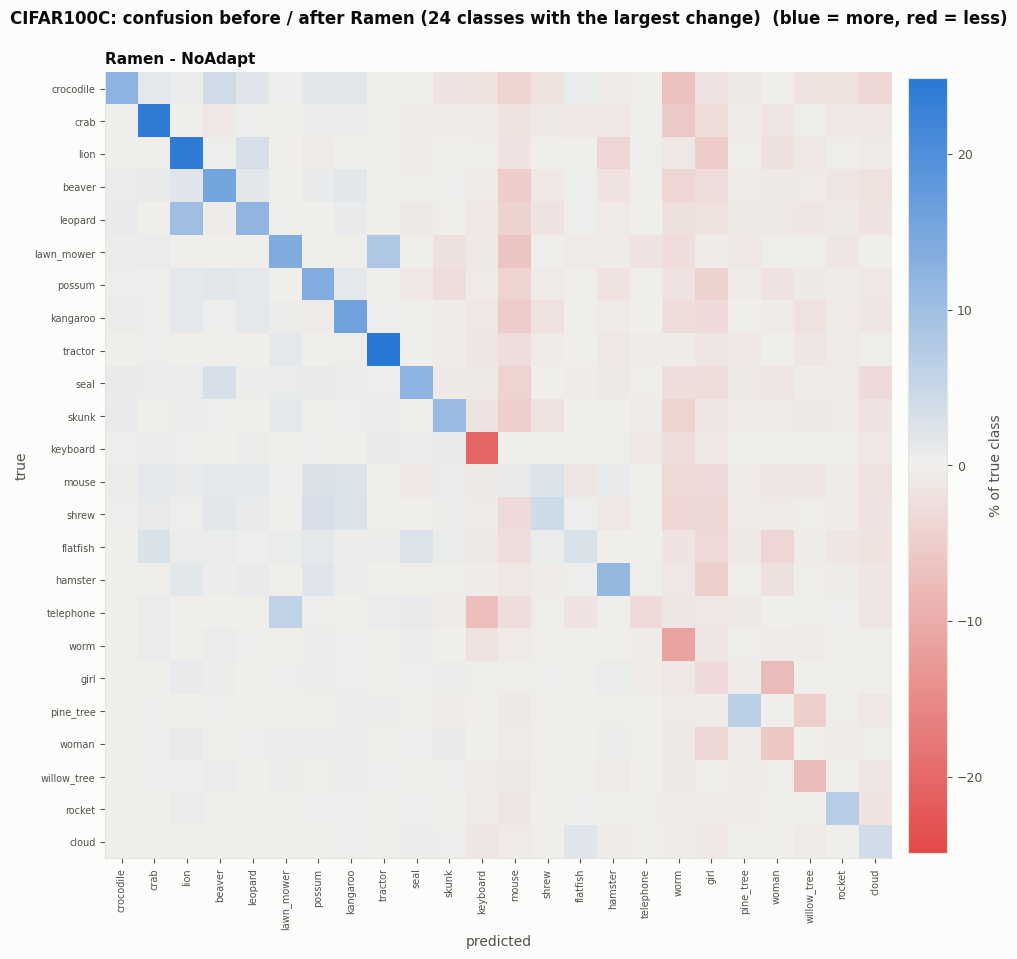

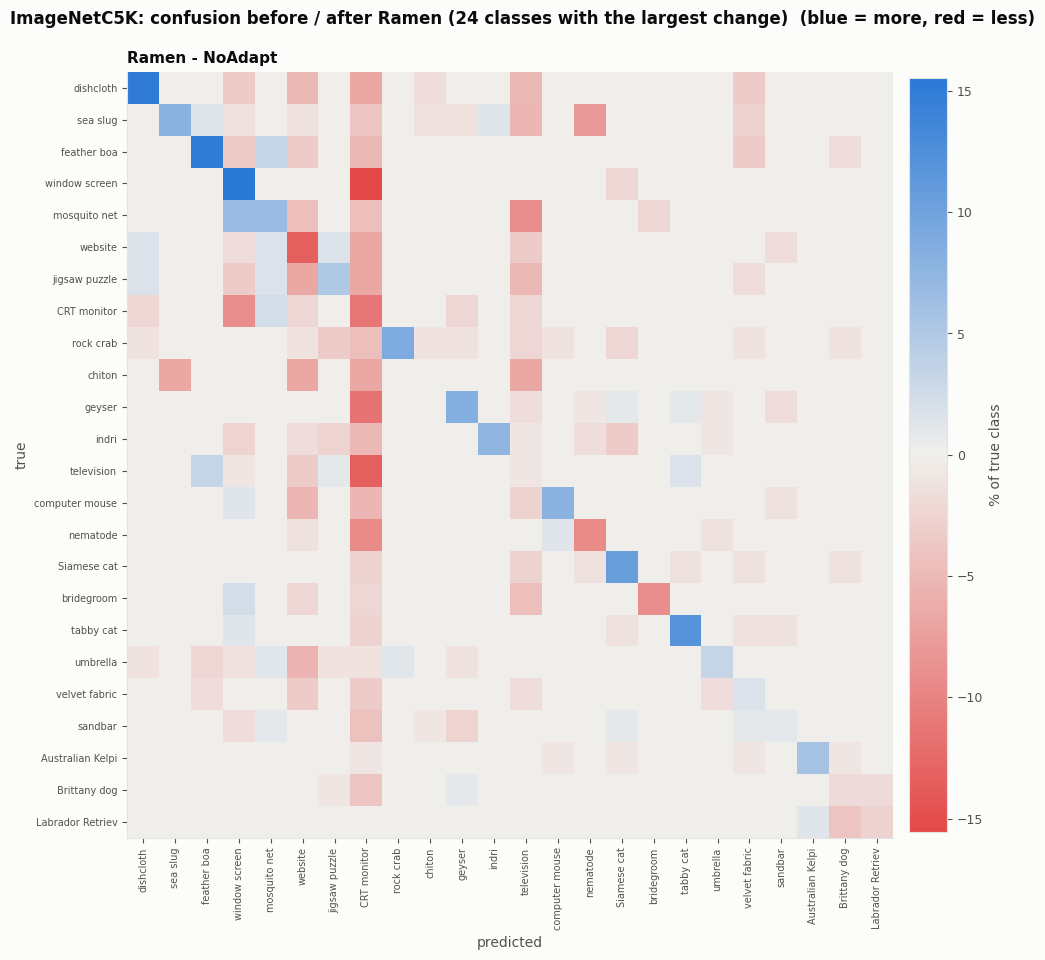

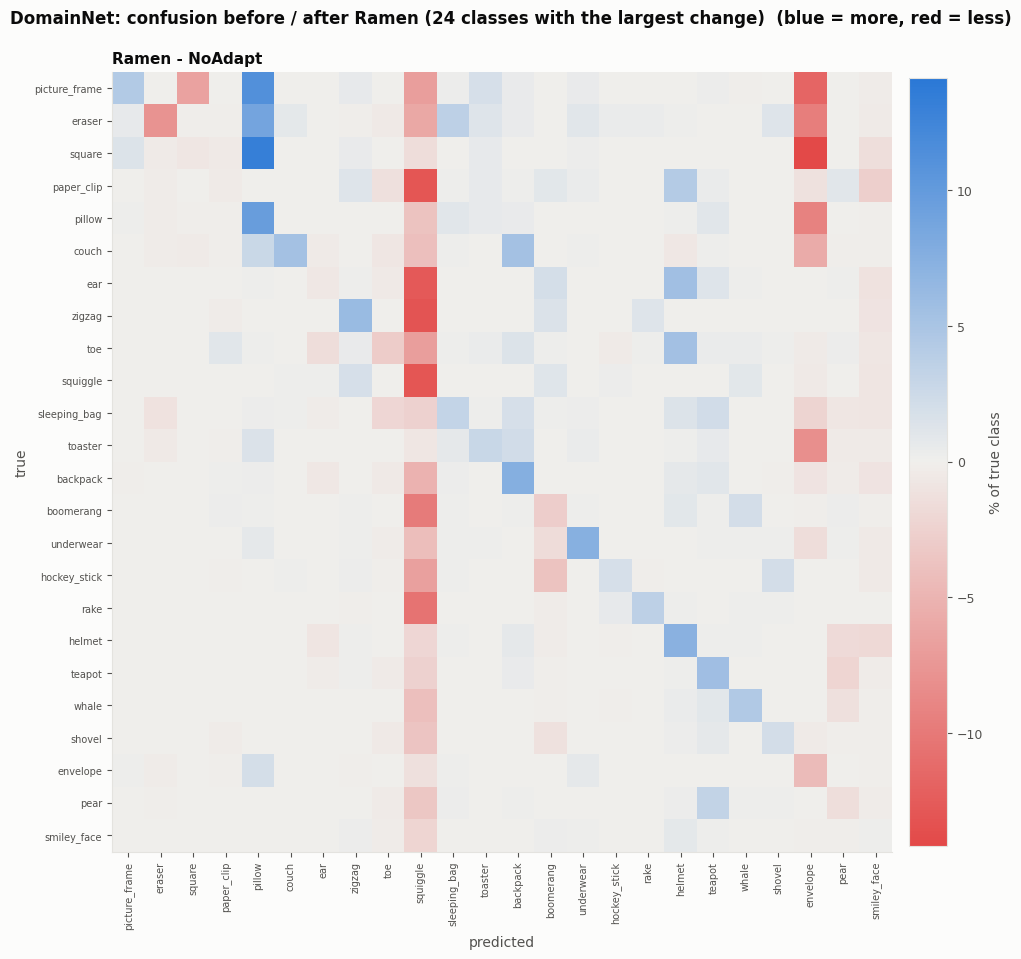

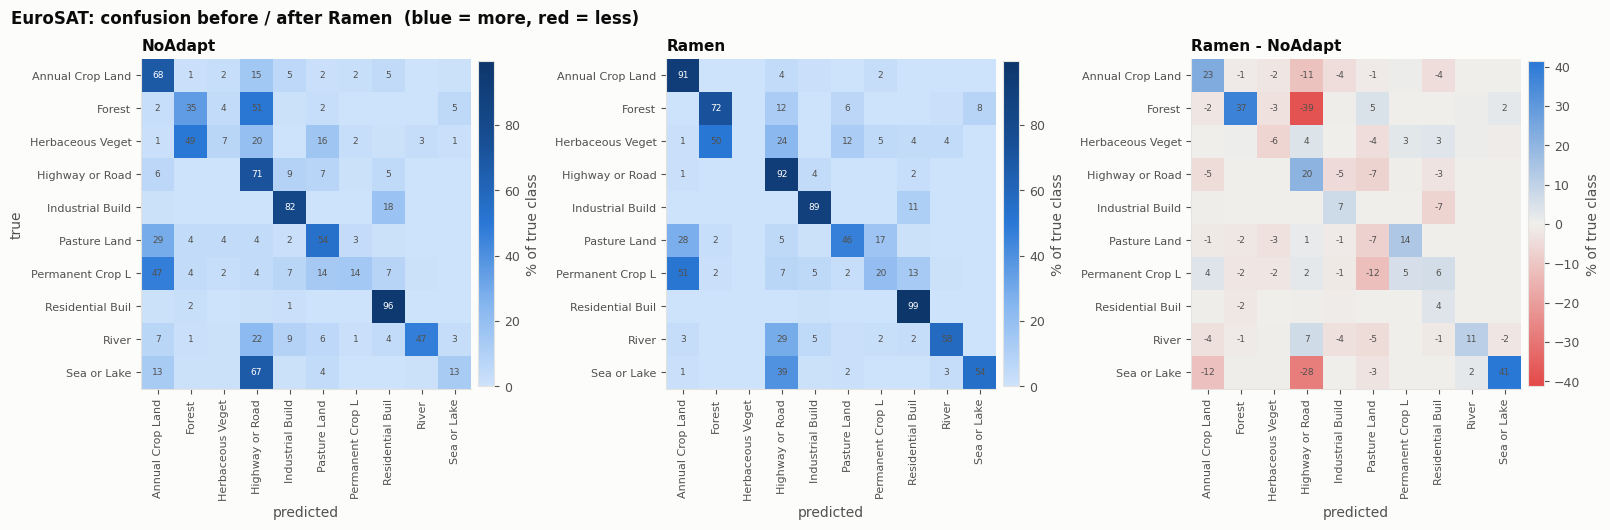

In [16]:
for ds, r in res.items():
    cs.plot_delta_confusion(ds, r)

## 8. Findings
Numbers are means over seeds 0-4 unless marked seed 0. DomainNet accuracies here are sample-weighted (52.83 → 54.55); the earlier notebooks report the domain average (55.37 → 56.80).

**1. Ramen dissolves domain-specific attractors.** Zero-shot CLIP under a shift collapses each domain's errors onto a few classes. Ramen spreads them out:
- The distance between the predicted and the true class distribution, per domain, drops on every dataset (TV: C10 16.5 → 9.6, C100 33.5 → 23.9, ImageNet-C 44.1 → 34.9, DomainNet 25.2 → 23.1, EuroSAT 29.8 → 25.1).
- Errors land in many more classes (effective destinations: ImageNet-C 52 → 76% of classes, DomainNet 41 → 65%, C100 69 → 83%). The top-5 destinations take far less of the error mass (ImageNet-C 13.3 → 3.1%, DomainNet 27.4 → 12.7%).
- Named attractors:
  - **CRT monitor**: 3,178 excess predictions → 232. It took 28% of the gaussian-noise errors; afterwards no class takes more than 1.6%.
  - **website**: +1,314 → −8.
  - **squiggle**: +43.6k → +10.4k; quickdraw's top destination goes from 29% to 7.8%.
  - **bird** on CIFAR-10-C: +12.8k → −339; it was 53% of the gaussian-noise errors.

**2. Ramen breaks the attractors without fixing their errors.** Within each domain (seed 0), a NoAdapt error that sits in a sink is fixed at the *same* rate as any other error (C100 20.5 vs 22.4%, ImageNet-C 12.7 vs 13.8%, DomainNet 7.1 vs 7.4%, C10 45.6 vs 43.3%). It is instead moved to a different wrong class 1.4-2.1x as often (ImageNet-C 61.6 vs 44.3%, DomainNet 48.8 vs 23.0%).
- So the de-sinking and the accuracy gain are two separate effects: the correction does not care whether an error was in a sink. The errors freed from a sink mostly become different errors.
- EuroSAT is the only exception: there, sink errors are fixed more often (43 vs 31%).

**3. It is not a class-prior shift.** A per-class logit bias on NoAdapt, fitted so it predicts each class exactly as often as Ramen does, recovers little of the gain:
- Globally it recovers 0.2-0.8 pts: 3% of Ramen's gain on ImageNet-C, 7% on C10/C100, 27% on EuroSAT, 33% on DomainNet.
- Fitted per domain it recovers 1.1-3.8 pts.
- It reproduces only 13-35% of the predictions Ramen changes.
- Even the oracle bias (fitted per domain to the *true* label counts) gains less than Ramen on 4/5 datasets. Its change to the confusion matrix points somewhere else (`dC_explained` −12 to −63% on ImageNet-C, DomainNet, EuroSAT).
- Most of `C1 − C0` is therefore per-sample reassignment, not a re-weighting of the classes.
- Exception: on DomainNet the oracle beats Ramen (+3.84 vs +1.73), so prior correction has headroom there that Ramen leaves unused. This is consistent with prior correction stacking on Ramen (see `findings_and_directions.md`).

**4. Most of what Ramen does is reshuffle errors.** It changes 22-53% of predictions. On the large label spaces, moving a sample from one wrong class to another is the biggest flow:

| Dataset | wrong → other wrong | fixed | broken |
|---|---|---|---|
| CIFAR-100-C | 29.1% | 13.6% | 4.5% |
| ImageNet-C | 39.1% | 9.6% | 3.8% |
| DomainNet | 16.6% | 3.5% | 1.7% |

**5. Where errors are reshuffled, they get closer to the true class on fine-grained data, but not on DomainNet.**
- On C100, ImageNet-C and EuroSAT the remaining errors are nearer misses:
  - Neighbour rank: 0.28 → 0.22, 0.20 → 0.16, 0.43 → 0.36.
  - Same superclass: C100 24.6 → 29.0%, EuroSAT 42.1 → 50.9%, C10 77.6 → 82.8%.
  - 56-61% of the wrong-to-wrong moves go to a class closer to the true class.
- Confusions become more mutual and less one-way (asymmetry: C10 44.8 → 34.8, C100 66.9 → 57.6, DomainNet 76.1 → 72.0; ImageNet-C only 88.2 → 86.8).
- On DomainNet the errors freed from squiggle and envelope go to *less* similar classes (rank 0.20 → 0.23; only 42% of the moves get closer). C10 is about neutral (46%).

**6. Ramen grows attractors of its own.**
- **CIFAR-10-C:** deer goes from 4.7k fewer predictions than images to 4.2k more, and is Ramen's top error destination in 11/15 corruptions. Truck and horse also gain.
- **DomainNet:** pillow (+365 → +5.9k), teapot, helmet.
- **EuroSAT:** Herbaceous Vegetation Land collapses (predicted at 0.01x its share; accuracy 6.7 → 0.3%). Asymmetry rises 85.6 → 93.7: a one-way drain.
- 10-18% of Ramen's broken samples (C100, ImageNet-C, DomainNet) land in classes that only Ramen turns into a domain sink.

**7. Who gains depends on the label-space size.**
- **Small label spaces level up.** Spearman(NoAdapt class accuracy, gain) is −0.42 on C10 and −0.38 on C100. The worst decile of classes goes 46.6 → 76.2% and 8.1 → 18.9%.
- **Large ones get richer.** The correlation is +0.11 on ImageNet-C and +0.21 on DomainNet. DomainNet's worst decile stays flat (19.6 → 19.4%); EuroSAT's falls (6.7 → 0.3%, the Herbaceous collapse).

**What this means for the method**
- Ramen's adapted features undo the shift-induced collapse onto a few class embeddings. That collapse is a property of the class marginal, and Ramen addresses it only partly and indirectly. This is why an explicit prior correction stacks with Ramen.
- Ramen's gain comes from a separate per-sample correction that ignores attractors.
- The biggest remaining target is the wrong-to-wrong churn: 39% of ImageNet-C samples, 60% of which move toward the true class. A re-ranking among the true class's neighbours, e.g. the kNN smoothing already tried on CIFAR, could convert some of these.

*Caveats:* class similarity uses prototypes from true labels, so it is a diagnostic, not a usable signal. The per-domain bias on ImageNet-C has 15,000 parameters for 75k samples, which flatters it. Sinks use a fixed 2x threshold.
